# DS3000 Project — Group 04
## Stage 1: Data Understanding and Baselines

Dataset: Plant Leaf Diseases

Proposed objective: Data organization and Simple models


In [10]:
import json
from pathlib import Path

data_folder = Path("data/plant_leaf_diseases")

def load_annotations(split):
    with open(data_folder / split / "_annotations.coco.json") as f:
        return json.load(f)

train_annotations = load_annotations("train")
valid_annotations = load_annotations("valid")
test_annotations = load_annotations("test")

#opens jason file and loads it into a dictionary called train_annotations

print("Training images:", len(train_annotations["images"]))
print("Validation images:", len(valid_annotations["images"]))
print("Test images:", len(test_annotations["images"]))
print("Annotations:", len(train_annotations["annotations"]))

#categories definitions are identical in all splits.
for category in train_annotations["categories"]:
    print(category["id"], " ", category["name"])

Training images: 3426
Validation images: 428
Test images: 428
Annotations: 11885
0   leaves
1   Apple Scab Leaf
2   Apple leaf
3   Apple rust leaf
4   Bell_pepper leaf
5   Bell_pepper leaf spot
6   Blueberry leaf
7   Cherry leaf
8   Corn Gray leaf spot
9   Corn leaf blight
10   Corn rust leaf
11   Peach leaf
12   Potato leaf
13   Potato leaf early blight
14   Potato leaf late blight
15   Raspberry leaf
16   Soyabean leaf
17   Soybean leaf
18   Squash Powdery mildew leaf
19   Strawberry leaf
20   Tomato Early blight leaf
21   Tomato Septoria leaf spot
22   Tomato leaf
23   Tomato leaf bacterial spot
24   Tomato leaf late blight
25   Tomato leaf mosaic virus
26   Tomato leaf yellow virus
27   Tomato mold leaf
28   Tomato two spotted spider mites leaf
29   grape leaf
30   grape leaf black rot


In [11]:
# Store the unique categories found in each image


def get_image_labels(annotations):
    image_labels = {}
    for image in annotations["images"]:
        image_id = image["id"]
        image_labels[image_id] = set()

    for annotation in annotations["annotations"]:
        image_id = annotation["image_id"]
        category_id = annotation["category_id"]

        if category_id == 17:
            category_id = 16  #merge two soya beans together

        image_labels[image_id].add(category_id)
    return image_labels

test_image_labels = get_image_labels(test_annotations)
valid_image_labels = get_image_labels(valid_annotations)
train_image_labels = get_image_labels(train_annotations)


# Count images by how many different categories they contain
def print_image_label_stats(image_labels):
    print("No category:", 
          sum(len(labels) == 0 for labels in image_labels.values()))

    print("Exactly one category:",
          sum(len(labels) == 1 for labels in image_labels.values()))

    print("Multiple categories:",
          sum(len(labels) > 1 for labels in image_labels.values()))
print_image_label_stats(test_image_labels)
print_image_label_stats(valid_image_labels)
print_image_label_stats(train_image_labels)

No category: 1
Exactly one category: 425
Multiple categories: 2
No category: 2
Exactly one category: 422
Multiple categories: 4
No category: 16
Exactly one category: 3384
Multiple categories: 26


#Note
with out data set, the data comes pre distributed 80% 10%, 10%, because of this we are unable to clean the data set prior to splitting, this results in a small alteration in the splits for test and validation being 425 and 422. which is  approx 80% 10% 10%

In [ ]:
# Remove images with no categories

def filter_single_category_images(image_labels):
    single_category_labels = {}
    excluded_ids = []
    for image_id, labels in image_labels.items():
        if len(labels) == 1:
            single_category_labels[image_id] = labels
        else:
            excluded_ids.append(image_id)
    return single_category_labels, excluded_ids


train_single_category_labels, train_excluded_ids = filter_single_category_images(train_image_labels)
test_single_category_labels, test_excluded_ids = filter_single_category_images(test_image_labels)
valid_single_category_labels, valid_excluded_ids = filter_single_category_images(valid_image_labels)

print("Training images with a single category:", len(train_single_category_labels))
print("Validation images with a single category:", len(valid_single_category_labels))
print("Test images with a single category:", len(test_single_category_labels))


# remove corrupt or un-available images.
from PIL import Image

def check_images(name, annotations, data_folder):
    missing_image_ids = []
    corrupt_image_ids = []
    for image in annotations["images"]:
        image_id = image["id"]
        image_path = data_folder / name / image["file_name"]

        if not image_path.is_file():
            missing_image_ids.append(image_id)
            continue

        try:
            with Image.open(image_path) as img:
                img.load()

        except (OSError, ValueError):
            corrupt_image_ids.append(image_id)
    return missing_image_ids, corrupt_image_ids

train_missing_image_ids, train_corrupt_image_ids = check_images("train", train_annotations, data_folder)
test_missing_image_ids, test_corrupt_image_ids = check_images("test", test_annotations, data_folder)
valid_missing_image_ids, valid_corrupt_image_ids = check_images("valid", valid_annotations, data_folder)


print("Training missing images:", len(train_missing_image_ids))
print("Training corrupt images:", len(train_corrupt_image_ids))
print("Validation missing images:", len(valid_missing_image_ids))
print("Validation corrupt images:", len(valid_corrupt_image_ids))
print("Test missing images:", len(test_missing_image_ids))
print("Test corrupt images:", len(test_corrupt_image_ids))

Training images with a single category: 3384
Validation images with a single category: 422
Test images with a single category: 425
Training missing images: 0
Training corrupt images: 0
Validation missing images: 0
Validation corrupt images: 0
Test missing images: 0
Test corrupt images: 0


#note
no images are corrupt or missing, no need to remove more 

In [6]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from PIL import Image

missing_image_ids = []
corrupt_image_ids = []

for image in train_annotations["images"]:
    image_id = image["id"]
    image_path = data_folder / "train" / image["file_name"]

    if not image_path.is_file():
        missing_image_ids.append(image_id)
        continue

    try:
        with Image.open(image_path) as img:
            img.load()

    except (OSError, ValueError):
        corrupt_image_ids.append(image_id)

print("Images checked:", len(train_annotations["images"]))

print("Missing images:", len(missing_image_ids))
print("Missing IDs:", missing_image_ids)

print("Unreadable images:", len(corrupt_image_ids))
print("Unreadable IDs:", corrupt_image_ids)

Images checked: 3426
Missing images: 0
Missing IDs: []
Unreadable images: 0
Unreadable IDs: []


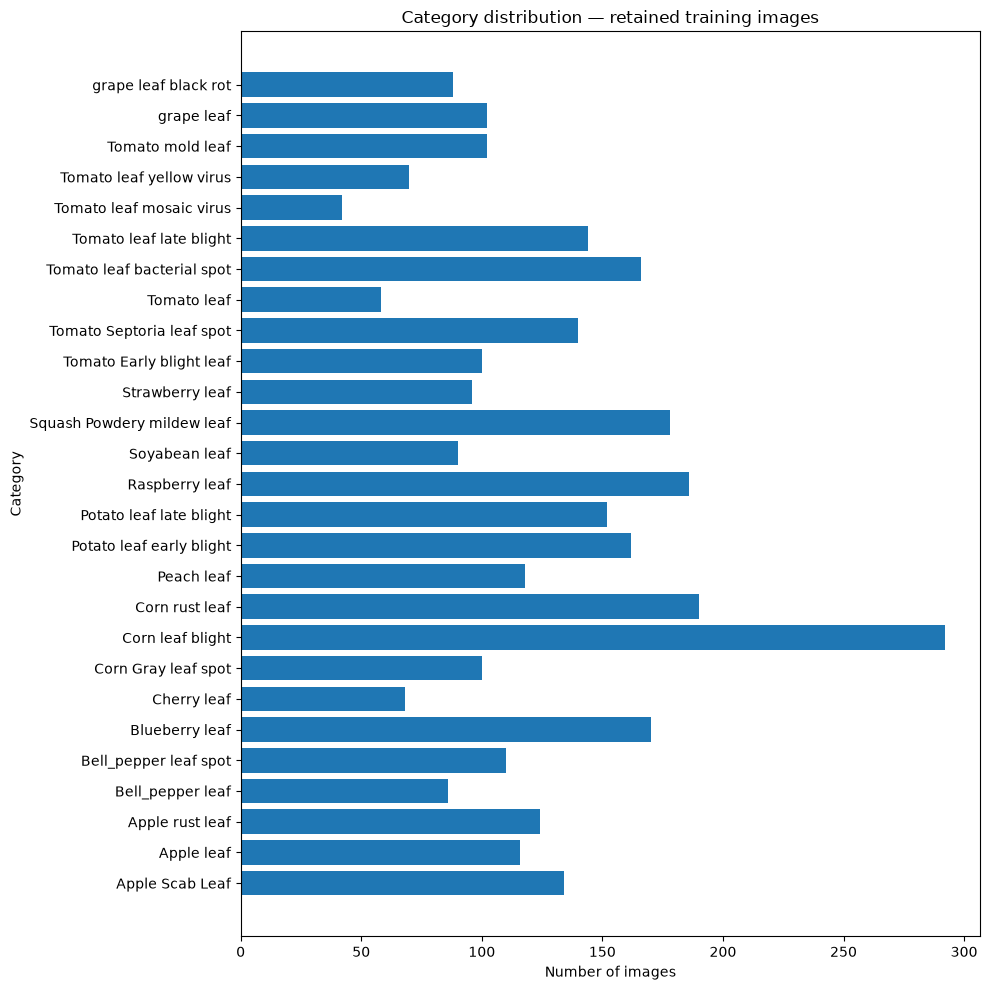

In [7]:
import matplotlib.pyplot as plt

category_counts = {}

for labels in single_category_labels.values():
    category_id = list(labels)[0]
    category_counts[category_id] = category_counts.get(category_id, 0) + 1

names = []
counts = []

for category in train_annotations["categories"]:
    category_id = category["id"]

    if category_id in category_counts:
        names.append(category["name"])
        counts.append(category_counts[category_id])

plt.figure(figsize=(10, 10))
plt.barh(names, counts)
plt.xlabel("Number of images")
plt.ylabel("Category")
plt.title("Category distribution — retained training images")
plt.tight_layout()
plt.show()